15:50:42 EDT WARNING: The monitor 'interval' field was left as its default      
             value, which will set it to 1 internally. A value of 1 means that  
             the data will be sampled at every time step, which may potentially 
             produce more data than desired, depending on the use case. To      
             reduce data storage, one may downsample the data by setting        
             'interval > 1' or by choosing alternative 'start' and 'stop' values
             for the time sampling. If you intended to use the highest          
             resolution time sampling, you may suppress this warning by         
             explicitly setting 'interval=1' in the monitor.                    

Pilot simulation:
  normalized kx = 0.400
  physical kx   = 1.2504e+01 rad/m
  target f      = 483.54 THz


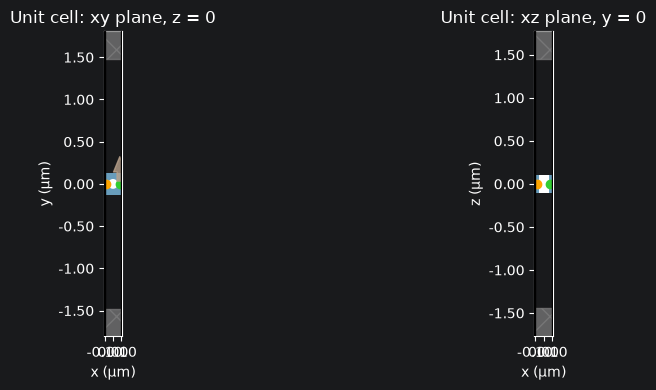

Submitting one pilot simulation only...


15:50:43 EDT Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=14353867;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d57a85b-2c81-4a86-a058-ebb641f1bc3c\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=14353868;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d57a85b-2c81-4a86-a058-ebb641f1bc3c\taskId]8;;\]8;id=14353867;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d57a85b-2c81-4a86-a058-ebb641f1bc3c\=]8;;\]8;id=14353869;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d57a85b-2c81-4a86-a058-ebb641f1bc3c\fdve]8;;\]8;id=14353867;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d57a85b-2c81-4a86-a058-ebb641f1bc3c\-2d57a85b-2c8]8;;\
             ]8;id=14353867;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d57a85b-2c81-4a86-a058-ebb641f1bc3c\1-4a86-a058-ebb641f1bc3c']8;;\.

             WARNING: Simulation final field decay value of 0.00598 is greater  
             than the simulation shutoff threshold of 1e-05. Consider running   
             the simulation again with a larger 'run_time' duration for more    
             accurate results.                                                  

Pilot completed.


In [4]:
# attempt to recreate Kevin Chen's thesis fig 4.1

import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

import tidy3d as td
from tidy3d import web


# ============================================================
# User settings
# ============================================================

# Geometry from the reference figure
a = 0.201      # lattice period [m]
W = 0.269      # beam width [m]
H = 0.202      # beam thickness [m]
r = 0.058       # air-hole radius [m]

# Assumed core material.
# The reference geometry is commonly associated with diamond/SnV devices.
n_core = 2.40

# Target SnV wavelength shown in the reference figure
lambda_snv = 0.62
f_snv = td.C_0 / lambda_snv

# Frequency range of the plotted band diagram
fmin = 300e12
fmax = 800e12

# Broadband source
f_source = 550e12
fwidth = 500e12

# Simulation duration.
# Longer duration improves frequency resolution but costs more.
run_time = 2.0e-12

# Air padding around the nanobeam in y and z
air_buffer = 5*W

# Use only nine k-points to reduce credits.
# 0.40 is deliberately included as the pilot point.
k_norms = np.linspace(0.30, 0.50, 9)

# The pilot simulation is used before the full sweep.
pilot_k = 0.40
pilot_key = f"k_{pilot_k:.3f}".replace(".", "p")

# Set this to True only after inspecting the pilot spectrum.
RUN_FULL_SWEEP = True

# Output directory
DATA_DIR = "tidy3d_bandstructure_data"
os.makedirs(DATA_DIR, exist_ok=True)


# ============================================================
# Materials and geometry
# ============================================================

core = td.Medium(permittivity=n_core**2)
air = td.Medium(permittivity=1.0)


def make_structures():
    """
    Create one unit cell:
        - dielectric nanobeam
        - cylindrical air hole through the thickness
    """

    beam = td.Structure(
        geometry=td.Box(
            center=(0, 0, 0),
            size=(a, W, H),
        ),
        medium=core,
        name="dielectric_beam",
    )

    hole = td.Structure(
        geometry=td.Cylinder(
            center=(0, 0, 0),
            radius=r,
            length=H + 1e-9,
            axis=2,       # cylinder axis along z
        ),
        medium=air,
        name="air_hole",
    )

    # The hole is listed after the beam so it overrides the dielectric
    # in the overlapping cylindrical region.
    return [beam, hole]


# ============================================================
# Sources and monitors
# ============================================================

def make_sources():
    """
    Use an Ey-oriented point dipole inside the dielectric.

    The hole is centered at x=0. Since r=58 nm and 0.4*a=80.4 nm,
    x=0.4*a lies in the dielectric rather than inside the hole.
    """

    source = td.PointDipole(
        center=(0.40 * a, 0, 0),
        polarization="Ey",
        source_time=td.GaussianPulse(
            freq0=f_source,
            fwidth=fwidth,
        ),
        name="Ey_dipole",
    )

    return [source]


def make_monitors():
    """
    The monitor is placed away from the source to reduce direct-source
    contamination in the spectrum.
    """

    monitor = td.FieldTimeMonitor(
        fields=["Ey"],
        center=(-0.40 * a, 0, 0),
        size=(0, 0, 0),
        start=0,
        name="field_time",
    )

    return [monitor]


# ============================================================
# Simulation construction
# ============================================================

def make_simulation(k_norm):
    """
    Construct the FDTD simulation for a normalized Bloch wavevector

        k_norm = k_x / (2*pi/a).

    Tidy3D's Boundary.bloch() expects this normalized value directly.
    """

    boundary_spec = td.BoundarySpec(
        x=td.Boundary.bloch(k_norm),
        y=td.Boundary.pml(),
        z=td.Boundary.pml(),
    )

    sim = td.Simulation(
        center=(0, 0, 0),
        size=(
            a,
            W + 2 * air_buffer,
            H + 2 * air_buffer,
        ),
        grid_spec=td.GridSpec.auto(
            min_steps_per_wvl=20,
        ),
        structures=make_structures(),
        sources=make_sources(),
        monitors=make_monitors(),
        boundary_spec=boundary_spec,
        run_time=run_time,
        courant=0.99,
    )

    return sim


# ============================================================
# No-credit local validation and visualization
# ============================================================

pilot_sim = make_simulation(pilot_k)

print("Pilot simulation:")
print(f"  normalized kx = {pilot_k:.3f}")
print(f"  physical kx   = {pilot_k * 2*np.pi/a:.4e} rad/m")
print(f"  target f      = {f_snv/1e12:.2f} THz")

# This validates the simulation object locally.
# It does not submit a cloud job.
pilot_sim.validate_pre_upload()

# Plot geometry before using any credits.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

pilot_sim.plot(z=0, ax=axes[0])
axes[0].set_title("Unit cell: xy plane, z = 0")

pilot_sim.plot(y=0, ax=axes[1])
axes[1].set_title("Unit cell: xz plane, y = 0")

plt.tight_layout()
plt.show()

# ============================================================
# One-credit pilot simulation
# ============================================================

print("Submitting one pilot simulation only...")

pilot_data_path = os.path.join(
    DATA_DIR,
    f"pilot_{pilot_key}.hdf5",
)

pilot_data = web.run(
    simulation=pilot_sim,
    task_name=f"bandstructure_pilot_{pilot_key}",
    path=pilot_data_path,
)

print("Pilot completed.")

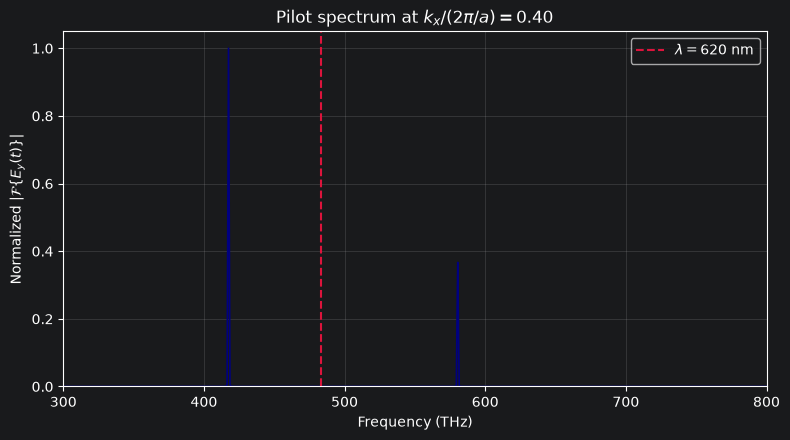

In [2]:

# ============================================================
# Spectrum extraction
# ============================================================

def extract_time_trace(sim_data, monitor_name="field_time", field_name="Ey"):
    """
    Extract a one-dimensional field-time trace from a point FieldTimeMonitor.

    Compatible with Tidy3D versions where FieldTimeData does not have
    a top-level .time attribute.
    """

    monitor_data = sim_data[monitor_name]

    # Get the field component, e.g. monitor_data.Ey
    field_da = getattr(monitor_data, field_name)

    # The time coordinate belongs to the field DataArray
    if "t" not in field_da.coords:
        raise RuntimeError(
            f"No 'time' coordinate found. "
            f"Available coordinates: {list(field_da.coords)}"
        )

    time = np.asarray(field_da.coords["t"].values)

    # Convert DataArray to NumPy array
    values = np.asarray(field_da.values)

    # Find which axis corresponds to time
    if "t" not in field_da.dims:
        raise RuntimeError(
            f"No 'time' dimension found. "
            f"Available dimensions: {field_da.dims}"
        )

    time_axis = field_da.dims.index("t")

    # Move time to axis 0
    values = np.moveaxis(values, time_axis, 0)

    # Collapse all remaining singleton/spatial dimensions.
    # For a point monitor, this should produce shape (Nt,).
    values = values.reshape(len(time), -1)

    if values.shape[1] != 1:
        print(
            f"Warning: monitor contains {values.shape[1]} spatial samples. "
            "Using the first one."
        )

    signal = values[:, 0]

    if len(time) != len(signal):
        raise RuntimeError(
            f"Time and signal lengths differ: "
            f"{len(time)} versus {len(signal)}"
        )

    return time, signal


def calculate_spectrum(sim_data):
    """
    Calculate a positive-frequency spectrum from Ey(t).
    """

    time, signal = extract_time_trace(sim_data)

    # Remove DC offset
    signal = signal - np.mean(signal)

    # Window the time signal to reduce FFT sidelobes.
    # This works for real or complex Bloch-field data.
    window = np.hanning(len(signal))
    signal_windowed = signal * window

    dt = np.median(np.diff(time))
    fft_values = np.fft.fft(signal_windowed)
    fft_freqs = np.fft.fftfreq(len(signal), d=dt)

    positive = (
        (fft_freqs > fmin) &
        (fft_freqs < fmax)
    )

    freqs = fft_freqs[positive]
    spectrum = np.abs(fft_values[positive])

    # Normalize for plotting and peak detection
    if np.max(spectrum) > 0:
        spectrum = spectrum / np.max(spectrum)

    return freqs, spectrum


pilot_freqs, pilot_spectrum = calculate_spectrum(pilot_data)

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    pilot_freqs / 1e12,
    pilot_spectrum,
    color="navy",
    linewidth=1.2,
)

ax.axvline(
    f_snv / 1e12,
    color="crimson",
    linestyle="--",
    linewidth=1.5,
    label=r"$\lambda=620$ nm",
)

ax.set_xlabel("Frequency (THz)")
ax.set_ylabel(r"Normalized $|\mathcal{F}\{E_y(t)\}|$")
ax.set_title(rf"Pilot spectrum at $k_x/(2\pi/a)={pilot_k:.2f}$")
ax.set_xlim(fmin / 1e12, fmax / 1e12)
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

In [3]:
# ============================================================
# Peak extraction
# ============================================================

def extract_peaks(freqs, spectrum):
    """
    Extract candidate band frequencies from a normalized spectrum.

    The thresholds are intentionally moderate because leaky
    photonic-crystal modes can be broad.
    """

    if len(freqs) < 3:
        return np.array([])

    df = np.median(np.diff(freqs))

    # Prevent neighboring FFT bins from being interpreted as
    # separate physical resonances.
    min_peak_spacing = 3e12
    distance_bins = max(1, int(min_peak_spacing / df))

    peak_indices, properties = find_peaks(
        spectrum,
        height=0.05,
        prominence=0.02,
        distance=distance_bins,
    )

    peak_freqs = freqs[peak_indices]

    return peak_freqs


pilot_peak_freqs = extract_peaks(
    pilot_freqs,
    pilot_spectrum,
)

print("Pilot peaks:")
for frequency in pilot_peak_freqs:
    print(f"  {frequency / 1e12:8.2f} THz")

Pilot peaks:
    417.49 THz
    580.49 THz


In [5]:
# ============================================================
# Full sweep, excluding the pilot point
# ============================================================

if not RUN_FULL_SWEEP:
    print(
        "Full sweep disabled. Set RUN_FULL_SWEEP = True "
        "after checking the pilot spectrum."
    )
else:
    # Reuse the pilot data so that k_norm=0.40 is not submitted again.
    all_data = {
        pilot_key: pilot_data,
    }

    simulations = {}

    for k_norm in k_norms:
        key = f"k_{k_norm:.3f}".replace(".", "p")

        if np.isclose(k_norm, pilot_k):
            continue

        simulations[key] = make_simulation(k_norm)

    print(f"Pilot reused at k_norm={pilot_k:.3f}.")
    print(f"Submitting {len(simulations)} additional simulations.")

    batch = web.Batch(
        simulations=simulations,
        verbose=True,
    )

    batch_data = batch.run(
        path_dir=DATA_DIR,
    )

    all_data.update(batch_data)

    print("Full sweep completed.")

15:52:04 EDT WARNING: The monitor 'interval' field was left as its default      
             value, which will set it to 1 internally. A value of 1 means that  
             the data will be sampled at every time step, which may potentially 
             produce more data than desired, depending on the use case. To      
             reduce data storage, one may downsample the data by setting        
             'interval > 1' or by choosing alternative 'start' and 'stop' values
             for the time sampling. If you intended to use the highest          
             resolution time sampling, you may suppress this warning by         
             explicitly setting 'interval=1' in the monitor.                    

             WARNING: The monitor 'interval' field was left as its default      
             value, which will set it to 1 internally. A value of 1 means that  
             the data will be sampled at every time step, which may potentially 
             produce more data than desired, depending on the use case. To      
             reduce data storage, one may downsample the data by setting        
             'interval > 1' or by choosing alternative 'start' and 'stop' values
             for the time sampling. If you intended to use the highest          
             resolution time sampling, you may suppress this warning by         
             explicitly setting 'interval=1' in the monitor.                    

             WARNING: The monitor 'interval' field was left as its default      
             value, which will set it to 1 internally. A value of 1 means that  
             the data will be sampled at every time step, which may potentially 
             produce more data than desired, depending on the use case. To      
             reduce data storage, one may downsample the data by setting        
             'interval > 1' or by choosing alternative 'start' and 'stop' values
             for the time sampling. If you intended to use the highest          
             resolution time sampling, you may suppress this warning by         
             explicitly setting 'interval=1' in the monitor.                    

             WARNING: The monitor 'interval' field was left as its default      
             value, which will set it to 1 internally. A value of 1 means that  
             the data will be sampled at every time step, which may potentially 
             produce more data than desired, depending on the use case. To      
             reduce data storage, one may downsample the data by setting        
             'interval > 1' or by choosing alternative 'start' and 'stop' values
             for the time sampling. If you intended to use the highest          
             resolution time sampling, you may suppress this warning by         
             explicitly setting 'interval=1' in the monitor.                    

             WARNING: The monitor 'interval' field was left as its default      
             value, which will set it to 1 internally. A value of 1 means that  
             the data will be sampled at every time step, which may potentially 
             produce more data than desired, depending on the use case. To      
             reduce data storage, one may downsample the data by setting        
             'interval > 1' or by choosing alternative 'start' and 'stop' values
             for the time sampling. If you intended to use the highest          
             resolution time sampling, you may suppress this warning by         
             explicitly setting 'interval=1' in the monitor.                    

             WARNING: The monitor 'interval' field was left as its default      
             value, which will set it to 1 internally. A value of 1 means that  
             the data will be sampled at every time step, which may potentially 
             produce more data than desired, depending on the use case. To      
             reduce data storage, one may downsample the data by setting        
             'interval > 1' or by choosing alternative 'start' and 'stop' values
             for the time sampling. If you intended to use the highest          
             resolution time sampling, you may suppress this warning by         
             explicitly setting 'interval=1' in the monitor.                    

... (14 outputs left out)

             WARNING: Simulation final field decay value of 0.00662 is greater  
             than the simulation shutoff threshold of 1e-05. Consider running   
             the simulation again with a larger 'run_time' duration for more    
             accurate results.                                                  

             WARNING: Simulation final field decay value of 0.00783 is greater  
             than the simulation shutoff threshold of 1e-05. Consider running   
             the simulation again with a larger 'run_time' duration for more    
             accurate results.                                                  

             WARNING: Simulation final field decay value of 0.00792 is greater  
             than the simulation shutoff threshold of 1e-05. Consider running   
             the simulation again with a larger 'run_time' duration for more    
             accurate results.                                                  

Full sweep completed.


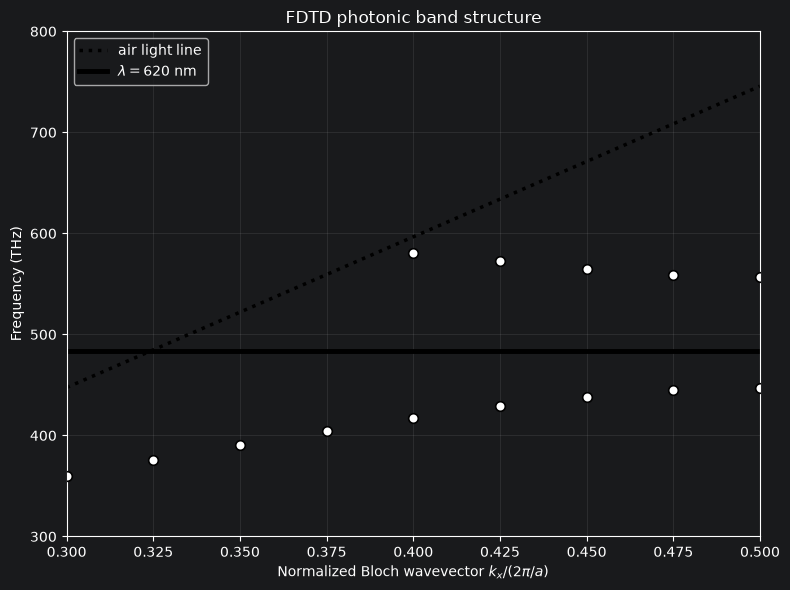

In [6]:
# ============================================================
# Construct and plot the band diagram
# ============================================================

if RUN_FULL_SWEEP:

    band_data = {}

    for k_norm in k_norms:
        key = f"k_{k_norm:.3f}".replace(".", "p")

        sim_data = all_data[key]

        freqs, spectrum = calculate_spectrum(sim_data)
        peaks = extract_peaks(freqs, spectrum)

        band_data[k_norm] = peaks

    # Light line:
    #
    # f_light = c * kx / (2*pi)
    #         = c * [k_norm * (2*pi/a)] / (2*pi)
    #         = c * k_norm / a
    #
    light_line = td.C_0 * k_norms / a

    fig, ax = plt.subplots(figsize=(8, 6))

    # Plot extracted FDTD peaks as open circles,
    # similar to the reference figure.
    for k_norm in k_norms:
        peaks = band_data[k_norm]

        if len(peaks) == 0:
            continue

        ax.scatter(
            np.full(len(peaks), k_norm),
            peaks / 1e12,
            s=48,
            facecolors="white",
            edgecolors="black",
            linewidths=1.2,
            zorder=3,
        )

    # Air light line
    ax.plot(
        k_norms,
        light_line / 1e12,
        "k:",
        linewidth=2.5,
        label="air light line",
    )

    # 620-nm reference line
    ax.axhline(
        f_snv / 1e12,
        color="black",
        linewidth=3.5,
        label=r"$\lambda=620$ nm",
    )

    ax.set_xlabel(r"Normalized Bloch wavevector $k_x/(2\pi/a)$")
    ax.set_ylabel("Frequency (THz)")
    ax.set_title("FDTD photonic band structure")
    ax.set_xlim(0.30, 0.50)
    ax.set_ylim(fmin / 1e12, fmax / 1e12)
    ax.grid(alpha=0.18)
    ax.legend(loc="upper left")

    plt.tight_layout()
    plt.show()

In [12]:
sim_data.plot_field(
    "field_time",
    "Ey",
    val="abs",
    z=0,
    t=sim_data["field_time"].Ey.t[-1],
)
plt.show()

11:02:30 EDT ERROR: Data after selection has 0 coordinates ([]), must be 2      
             spatial coordinates for plotting on plane. Please add keyword      
             arguments to `plot_field()` to select out the other coords.        

DataError: Data after selection has 0 coordinates ([]), must be 2 spatial coordinates for plotting on plane. Please add keyword arguments to `plot_field()` to select out the other coords.

In [14]:
print(sim_data["field_time"].Ey.t)

<xarray.ScalarFieldTimeDataArray 't' (t: 97517)> Size: 780kB
array([0.000000e+00, 2.050953e-17, 4.101905e-17, ..., 1.999966e-12,
       1.999986e-12, 2.000007e-12], shape=(97517,))
Coordinates:
  * t        (t) float64 780kB 0.0 2.051e-17 4.102e-17 ... 2e-12 2e-12 2e-12
Attributes:
    units:      sec
    long_name:  time
